# plutovizu — Sciences de la nature

API chaînable : chaque méthode retourne le graphique, on enchaîne les appels et on termine par `.show()`. Le thème **editorial** est appliqué dès l'import. Fiches détaillées (données attendues, paramètres) dans la [documentation](https://mr-kam.github.io/plutovizu/).

In [1]:
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from plutovizu import (Chart, cm, get_fonts, list_themes, set_theme, texture_class,
                       theme_context)

# Taille par défaut d'un graphique : 16 × 10 cm ; cm(largeur, hauteur) pour une autre taille.
# Export (save) : 400 dpi par défaut.

## Sciences de la nature

Un essai agronomique fictif : trois variétés de riz, cinq doses d'azote, quatre blocs.

In [2]:
rng = np.random.default_rng(3)
lignes = []
for variete, gain in [('Sahel-108', 0.0), ('IR-841', 0.7), ('Nerica-4', 1.3)]:
    for dose in [0, 30, 60, 90, 120]:
        for bloc in range(1, 5):
            lignes.append({'variete': variete, 'dose': dose, 'bloc': bloc,
                           'rendement': 2.5 + gain + 0.035 * dose - 0.00018 * dose ** 2
                                        + rng.normal(0, 0.3)})
essai = pd.DataFrame(lignes)
essai.head()

,variete,dose,bloc,rendement
0,Sahel-108,0,1,3.112276
1,Sahel-108,0,2,1.733300
2,Sahel-108,0,3,2.625430
3,Sahel-108,0,4,2.329669
4,Sahel-108,30,1,3.252205


### Régression : courbe de réponse à l'azote

Ajustement polynomial, bande de confiance à 95 %, équation et R².

{'coefs': array([-2.07043582e-04,  3.73229013e-02,  3.16931512e+00]), 'r2': np.float64(0.4819982877068384), 'p': None, 'n': 60}


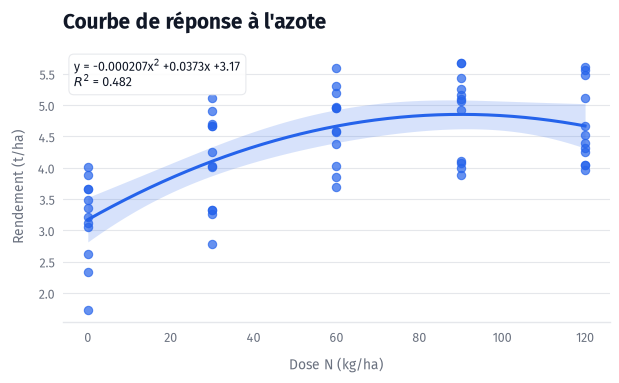

In [3]:
chart = (Chart(essai)
    .regression('dose', 'rendement', order=2)
    .title("Courbe de réponse à l'azote")
    .labels(xlabel='Dose N (kg/ha)', ylabel='Rendement (t/ha)')
    .tight_layout())
print(chart.regression_stats)
chart.show()

### Moyennes ± erreur et lettres de Tukey

Deux barres qui partagent une lettre ne diffèrent pas significativement (Tukey HSD, α = 5 %). Avec `hue`, les variétés sont comparées à l'intérieur de chaque dose.

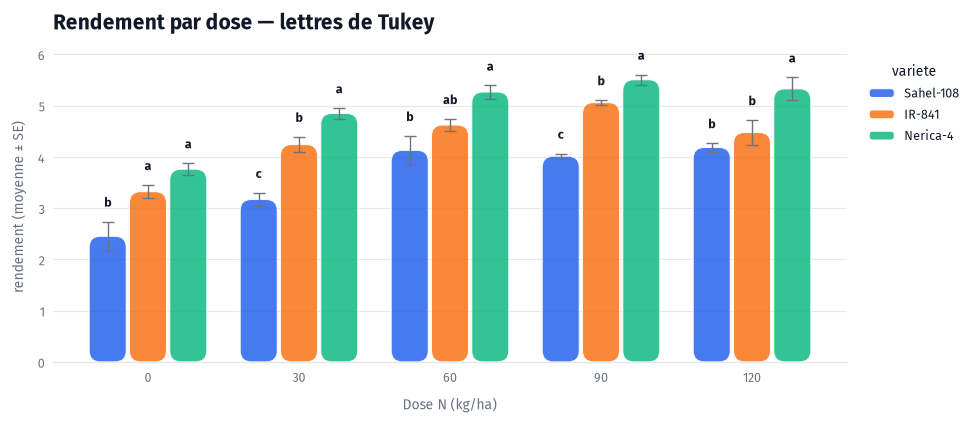

{(0, 'Sahel-108'): 'b',
 (0, 'IR-841'): 'a',
 (0, 'Nerica-4'): 'a',
 (30, 'Sahel-108'): 'c',
 (30, 'IR-841'): 'b',
 (30, 'Nerica-4'): 'a',
 (60, 'Sahel-108'): 'b',
 (60, 'IR-841'): 'ab',
 (60, 'Nerica-4'): 'a',
 (90, 'Sahel-108'): 'c',
 (90, 'IR-841'): 'b',
 (90, 'Nerica-4'): 'a',
 (120, 'Sahel-108'): 'b',
 (120, 'IR-841'): 'b',
 (120, 'Nerica-4'): 'a'}

In [4]:
chart = (Chart(essai, figsize=cm(25, 11))   # 15 barres, légende et lettres : plus large
    .mean_bar('dose', 'rendement', hue='variete', letters=True)
    .title('Rendement par dose — lettres de Tukey')
    .labels(xlabel='Dose N (kg/ha)')
    .tight_layout())
chart.show()
chart.tukey_letters

### Interaction et normalité des résidus

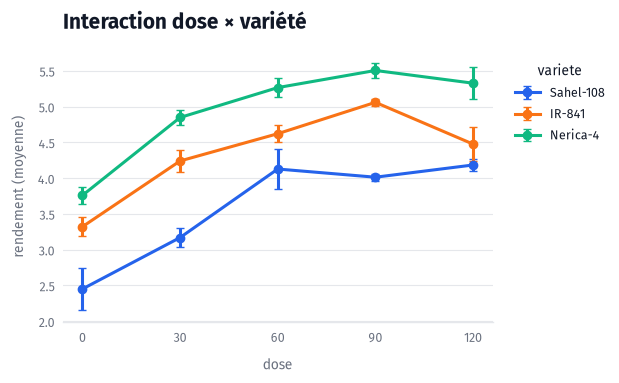

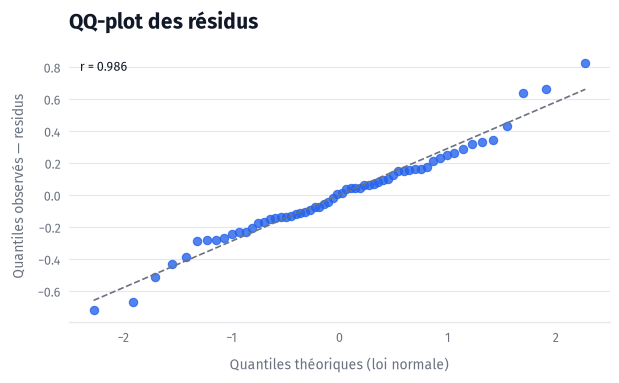

In [5]:
(Chart(essai)
    .interaction('dose', 'variete', 'rendement')
    .title('Interaction dose × variété')
    .tight_layout()
    .show())

essai['residus'] = essai['rendement'] - essai.groupby(['variete', 'dose'])['rendement'].transform('mean')
(Chart(essai)
    .qqplot('residus')
    .title('QQ-plot des résidus')
    .tight_layout()
    .show())

### ACP, dendrogramme et clustermap

Cinq caractères mesurés sur 20 variétés.

Variance expliquée (%) : [69.3 15.7  8.1]


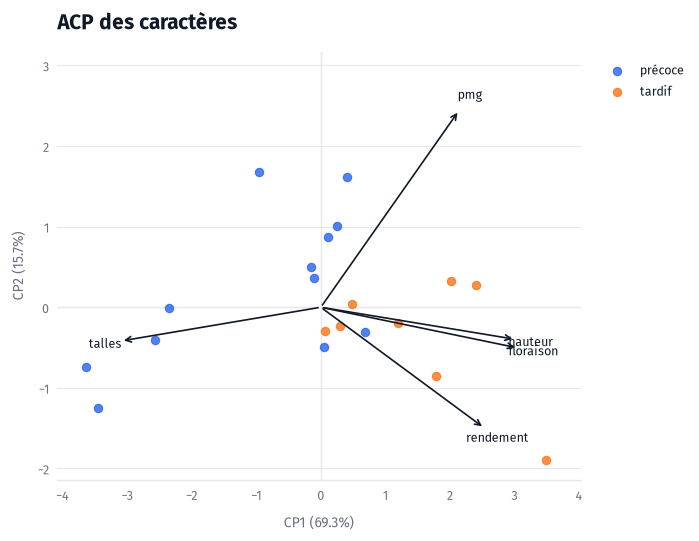

In [6]:
rng = np.random.default_rng(7)
n = 20
precocite = rng.normal(size=n)
caracteres = pd.DataFrame({
    'variete': [f'V{i:02d}' for i in range(n)],
    'cycle': np.where(precocite > 0, 'tardif', 'précoce'),
    'hauteur': 95 + 12 * precocite + rng.normal(0, 5, n),
    'floraison': 85 + 10 * precocite + rng.normal(0, 3, n),
    'talles': 12 - 2 * precocite + rng.normal(0, 1, n),
    'pmg': 25 + rng.normal(0, 2.5, n),
    'rendement': 4.5 + 0.5 * precocite + rng.normal(0, 0.4, n),
})

chart = Chart(caracteres, figsize=cm(18, 14)).pca_biplot(group='cycle').title('ACP des caractères').tight_layout()
print('Variance expliquée (%) :', (chart.pca['explained_variance_ratio'][:3] * 100).round(1))
chart.show()

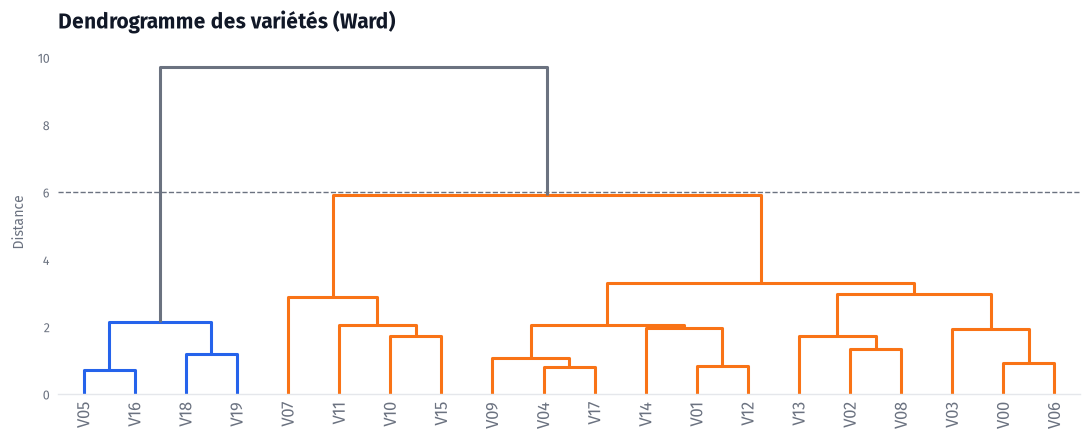

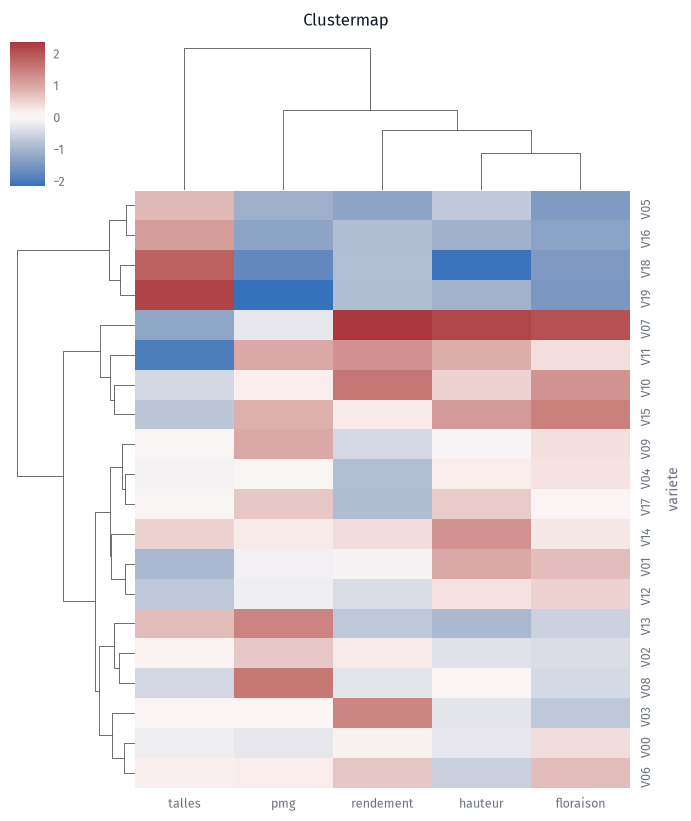

In [7]:
(Chart(caracteres, figsize=(11, 4.5))
    .dendrogram(labels='variete', color_threshold=6)
    .title('Dendrogramme des variétés (Ward)')
    .tight_layout()
    .show())

Chart(caracteres, figsize=(7, 8)).clustermap(labels='variete').title('Clustermap').show()

### Triangle des textures du sol (USDA)

`soil_texture` trace les 12 classes ; `texture_class` classe les échantillons sans tracer.

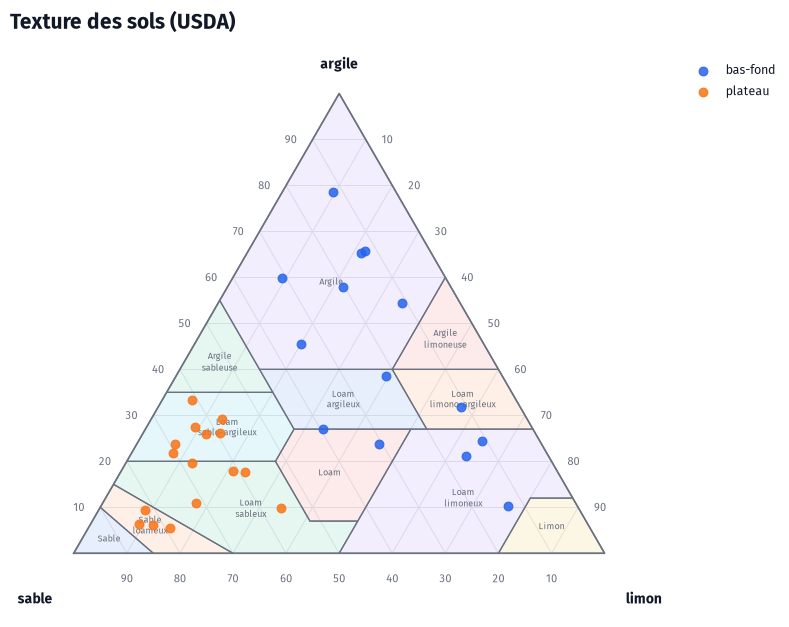

texture
Argile                  7
Loam sablo-argileux     7
Loam sableux            5
Sable loameux           4
Loam limoneux           3
Loam                    2
Loam argileux           1
Loam limono-argileux    1
Name: count, dtype: int64

In [8]:
rng = np.random.default_rng(11)
sols = pd.DataFrame({'zone': rng.choice(['bas-fond', 'plateau'], 30)})
sols['sable'] = np.where(sols['zone'] == 'plateau', rng.uniform(55, 85, 30), rng.uniform(10, 45, 30))
sols['argile'] = rng.uniform(5, 100 - sols['sable'] - 5)
sols['limon'] = 100 - sols['sable'] - sols['argile']

chart = (Chart(sols, figsize=(8, 7.5))
    .soil_texture('sable', 'limon', 'argile', group='zone')
    .title('Texture des sols (USDA)')
    .tight_layout())
chart.show()
chart.texture_classes.value_counts()

In [9]:
texture_class(40, 40, 20), texture_class(10, 80, 10), texture_class(20, 20, 60)

('Loam', 'Limon', 'Argile')

### Cercles imbriqués (circle packing)

Un cercle par culture, d'aire proportionnelle à la surface, regroupé par famille (calcul par circlify). `chart.circles` contient la position et le rayon de chaque cercle.

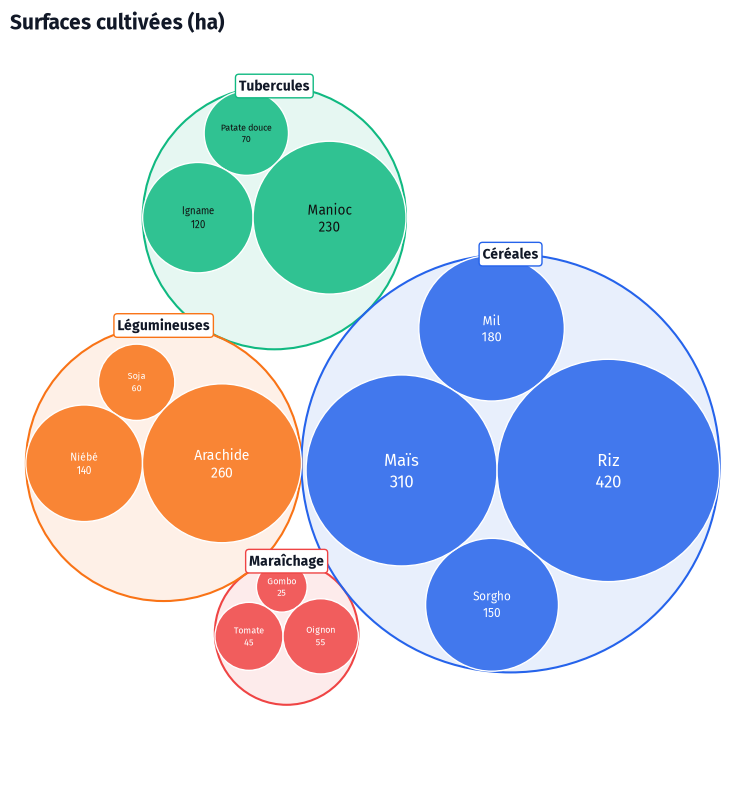

In [10]:
cultures = pd.DataFrame({
    'famille': ['Céréales'] * 4 + ['Légumineuses'] * 3 + ['Tubercules'] * 3 + ['Maraîchage'] * 3,
    'culture': ['Riz', 'Maïs', 'Mil', 'Sorgho', 'Niébé', 'Arachide', 'Soja',
                'Manioc', 'Igname', 'Patate douce', 'Tomate', 'Oignon', 'Gombo'],
    'surface': [420, 310, 180, 150, 140, 260, 60, 230, 120, 70, 45, 55, 25],
})

(Chart(cultures, figsize=(8, 8))
    .circle_packing('surface', labels='culture', group='famille', show_values=True)
    .title('Surfaces cultivées (ha)')
    .tight_layout()
    .show())

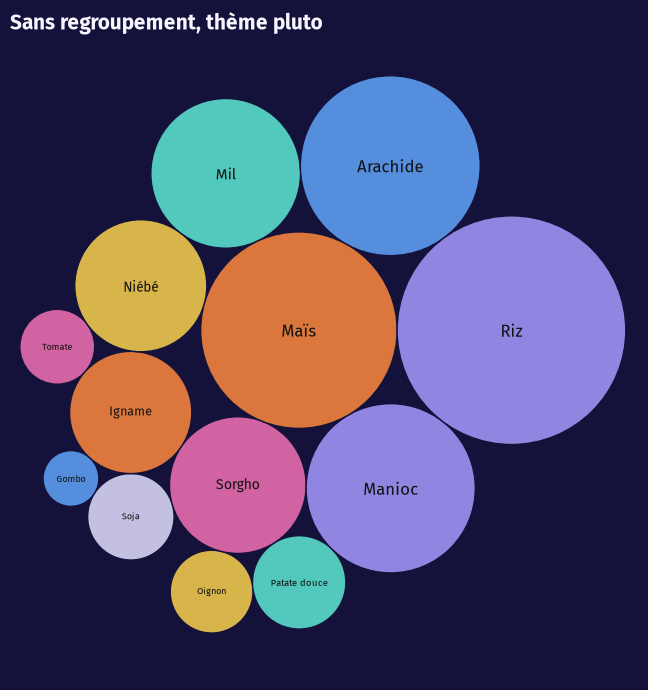

In [11]:
with theme_context('pluto'):
    (Chart(cultures, figsize=(7, 7))
        .circle_packing('surface', labels='culture')
        .title('Sans regroupement, thème pluto')
        .tight_layout()
        .show())